# IsoHarmonix: Data and Path Planner

**Team 9:** Alison Wu, Lisa Wang, Tiffany Chiang, Melody Huang · AI for Healthcare, Fall 2026

This notebook covers the first build tasks in our timeline:

| Weeks | Task | Owner | Section |
|---|---|---|---|
| 10/6 to 10/20 | DEAM loading, cleaning, coverage plot | A (Alison) | Parts 1 to 3 |
| 10/6 to 10/20 | Path planner + song retrieval | B (Lisa) | Parts 4 to 6 |

**Idea (Iso-Principle):** the first song matches the listener's current mood, and each
next song moves one step closer to the target mood. We compare this **iso-guided**
playlist with a **direct-to-target** playlist, where every song sits at the target mood.

**How to run:** run all cells from top to bottom. Part 0 explains where to put the data.

## 0. Setup

**Data.** Download the [DEAM dataset from Kaggle](https://www.kaggle.com/datasets/imsparsh/deam-mediaeval-dataset-emotional-analysis-in-music)
and unzip it into `data/DEAM/` (or set `DEAM_DATA_DIR` to that folder).
The folder layout inside does not matter, because we search for the files by name:

- `static_annotations_averaged_songs_1_2000.csv`
- `static_annotations_averaged_songs_2000_2058.csv`
- the MP3 clips, named `<song_id>.mp3` (leading zeros are fine; `.MP3` is fine)

**Colab:** if `DATA_DIR` is not found, the next cell tries to download the dataset with
`kagglehub` (you need a Kaggle account and API token). Do not commit `data/` or any MP3s.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 140)


def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "isoharmonix").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    return here


ROOT = _repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from isoharmonix.data import resolve_deam_dir

RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = resolve_deam_dir(ROOT)

if not DATA_DIR.exists():
    try:
        import kagglehub
        DATA_DIR = Path(kagglehub.dataset_download(
            "imsparsh/deam-mediaeval-dataset-emotional-analysis-in-music"))
    except Exception as e:
        raise FileNotFoundError(
            f"No data at {DATA_DIR}. Download DEAM from Kaggle and unzip it there, "
            "or set DEAM_DATA_DIR. Do not substitute unrelated audio."
        ) from e

print("Data folder:", DATA_DIR)

### Fixed rules

Our proposal says all rules are **fixed before the study** and then tested on new
participants. They are all in this one cell. Do not change them after the pilot.

In [ ]:
from isoharmonix.rules import (
    DISTANCE_METRIC,
    GAP_WARNING,
    N_STEPS,
    SCALE_MAX,
    SCALE_MIN,
    SPREAD_QUANTILE,
)

# Fixed before the pilot. Change them only in isoharmonix/rules.py, with the team.
assert (SCALE_MIN, SCALE_MAX, N_STEPS, DISTANCE_METRIC, SPREAD_QUANTILE, GAP_WARNING) == (
    1.0, 9.0, 5, "euclidean", 0.90, 1.0,
)

## 1. Load DEAM ratings *(Alison)*

DEAM has two song-level rating files. The headers contain spaces (for example
`" valence_mean"`) and the second file has extra columns, so we clean the column names
and keep only what we need: the mean and standard deviation (spread across raters) of
valence and arousal.

In [ ]:
from isoharmonix.data import load_annotations, scan_audio

raw_songs = load_annotations(DATA_DIR)
audio_scan = scan_audio(DATA_DIR)
audio = audio_scan.playable
print(
    f"{len(raw_songs)} songs with ratings, {audio_scan.mp3_count} MP3 files found, "
    f"{len(audio)} playable, {audio_scan.unreadable_count} unreadable"
)
raw_songs.describe().round(2)

## 2. Clean the data *(Alison)*

Rules from the Data Plan slide:

| Issue | What we do |
|---|---|
| Songs missing a rating, or missing/unreadable audio | Drop them. The audio check runs only if MP3 files were found. |
| Rating outside 1 to 9 | Drop them (sanity check). |
| Raters disagree (possible mislabels) | Spread = (valence_std + arousal_std) / 2. Drop songs above the 90th percentile. |

After cleaning, **each song is one point (valence, arousal)** on the same 1 to 9 scale
as the user's mood sliders.

In [ ]:
from isoharmonix.data import clean_songs

songs, cleaning_report = clean_songs(
    raw_songs,
    audio,
    require_audio=audio_scan.mp3_count > 0,
    unreadable_ids=audio_scan.unreadable_ids,
)
for key, value in cleaning_report.items():
    print(f"{key:<48} {value}")

(ROOT / "data").mkdir(parents=True, exist_ok=True)
songs.to_csv(ROOT / "data" / "songs_clean.csv", index=False)
songs.head()

In [ ]:
# Quick sanity checks. The spread cutoff is the one actually applied, which is
# computed after the audio filter when MP3s are present.
assert songs["song_id"].is_unique
assert songs[["valence", "arousal"]].stack().between(SCALE_MIN, SCALE_MAX).all()
if len(songs) and cleaning_report["Spread cutoff"] is not None:
    assert songs["spread"].max() <= cleaning_report["Spread cutoff"] + 1e-9
print("Cleaning checks passed")

## 3. Coverage plot *(Alison)*

DEAM songs are not spread evenly across the mood space. For every possible target
mood, we measure the **gap**: the distance to the closest song. A large gap means the
planner cannot find a song that really matches that target.

In [6]:
def nearest_gap(songs, points):
    nn = NearestNeighbors(n_neighbors=1, metric=DISTANCE_METRIC).fit(songs[["valence", "arousal"]].to_numpy())
    dist, _ = nn.kneighbors(np.asarray(points, dtype=float))
    return dist[:, 0]


def coverage_table(songs, step=1.0):
    axis = np.arange(SCALE_MIN, SCALE_MAX + 1e-9, step)
    vv, aa = np.meshgrid(axis, axis)
    pts = np.column_stack([vv.ravel(), aa.ravel()])
    gaps = nearest_gap(songs, pts)
    return pd.DataFrame({"valence": pts[:, 0], "arousal": pts[:, 1],
                         "gap": gaps, "covered": gaps <= GAP_WARNING})


grid = coverage_table(songs, step=1.0)   # the 81 integer slider settings
grid.to_csv(RESULTS_DIR / "coverage_grid.csv", index=False)

print(f"Median gap to the closest song: {grid['gap'].median():.2f}")
print(f"Max gap:                        {grid['gap'].max():.2f}")
print(f"Slider settings with a song within {GAP_WARNING}: {grid['covered'].mean():.1%}")
print("\nWorst-covered targets:")
grid.sort_values("gap", ascending=False).head(5).round(2)

Median gap to the closest song: 0.63
Max gap:                        3.07
Slider settings with a song within 1.0: 64.2%

Worst-covered targets:


,valence,arousal,gap,covered
72,1.0,9.0,3.07,False
8,9.0,1.0,2.75,False
73,2.0,9.0,2.47,False
63,1.0,8.0,2.44,False
74,3.0,9.0,2.06,False


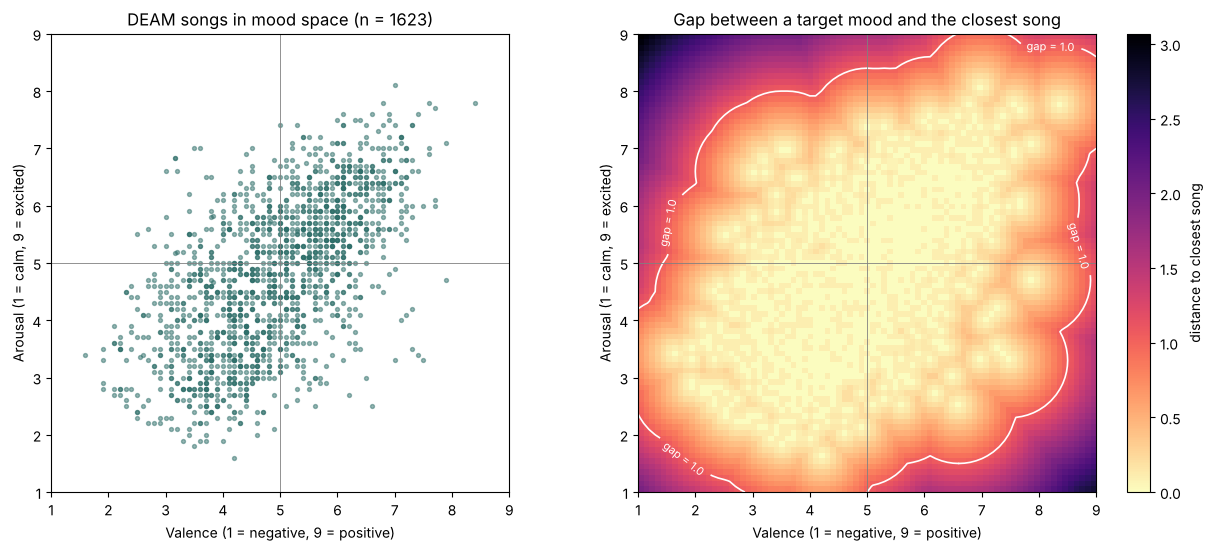

In [7]:
fine = coverage_table(songs, step=0.1)
n = int(round(np.sqrt(len(fine))))
gap_img = fine["gap"].to_numpy().reshape(n, n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), constrained_layout=True)
axes[0].scatter(songs["valence"], songs["arousal"], s=8, alpha=0.5, color="#2f6f6a")
axes[0].set_title(f"DEAM songs in mood space (n = {len(songs)})")

im = axes[1].imshow(gap_img, origin="lower", extent=(SCALE_MIN, SCALE_MAX, SCALE_MIN, SCALE_MAX),
                    cmap="magma_r")
cs = axes[1].contour(np.linspace(SCALE_MIN, SCALE_MAX, n), np.linspace(SCALE_MIN, SCALE_MAX, n),
                     gap_img, levels=[GAP_WARNING], colors="white", linewidths=1.2)
axes[1].clabel(cs, fmt={GAP_WARNING: f"gap = {GAP_WARNING}"}, fontsize=8)
fig.colorbar(im, ax=axes[1], label="distance to closest song")
axes[1].set_title("Gap between a target mood and the closest song")

for ax in axes:
    ax.set(xlim=(SCALE_MIN, SCALE_MAX), ylim=(SCALE_MIN, SCALE_MAX), aspect="equal",
           xlabel="Valence (1 = negative, 9 = positive)", ylabel="Arousal (1 = calm, 9 = excited)")
    ax.axhline(5, color="grey", lw=0.6)
    ax.axvline(5, color="grey", lw=0.6)

fig.savefig(RESULTS_DIR / "coverage_plot.png", dpi=150)
plt.show()

**What we see.** Most songs lie on a diagonal from sad/calm (bottom left) to
happy/excited (top right). The corners are almost empty: "very tense" (low valence,
high arousal) and "very calm and happy" (high valence, low arousal). The second corner
is a typical *target* for stress relief, so this matters for the study (see Part 7).

## 4. Path planner *(Lisa)*

- **2a. Iso-guided path:** 5 evenly spaced points from the current mood to the target
  mood. Point 1 = current mood (match), point 5 = target mood.
- **2b. Direct-to-target path (control):** all 5 points at the target mood, like a
  typical "calm" playlist.

In [ ]:
from isoharmonix.planner import Mood, direct_path, iso_path
from isoharmonix.rules import DIRECT, ISO

current, target = Mood(3, 7), Mood(7, 3)   # tense -> calm and content
print("Iso-guided points:\n", iso_path(current, target))
print("Direct-to-target points:\n", direct_path(target))

## 5. Song retrieval *(Lisa)*

For each waypoint we pick a DEAM song by Euclidean distance in valence-arousal
space. A participant never hears the same song twice, including across the two
playlists. The implementation is `isoharmonix/planner.py`, which this notebook
calls. Automated checks live in `tests/` (`python -m unittest discover -s tests -v`).

**Default allocation is `joint`.** Both playlists are filled by one minimum-cost
assignment (SciPy `linear_sum_assignment`), so the ten songs do not depend on
which playlist is built first. When several steps share a target, the matched
songs are dealt by how many steps each condition still has open, instead of
giving the closest block to whichever playlist ran first.

`allocation="iso_first"` is the original rule: build the iso playlist, then the
direct playlist from what remains. `allocation="direct_first"` reverses that
rule and is only for measuring the order effect. **Please approve `joint`
before the pilot.** Until then, pass `allocation="iso_first"` to reproduce the
earlier notebook.

Songs with a missing or undecodable audio file are not eligible once any MP3s
have been found. If no MP3s are found, the ratings-only catalog is still used
for these checks, and `audio_path` stays empty. That catalog is not playback-ready.

Each chosen song keeps the numbers for the **"why this song" card**.

In [ ]:
from isoharmonix.planner import SongRetriever, build_session, match_quality

retriever = SongRetriever(songs)
# joint is the proposed default. The committed results/example_session.csv was
# produced earlier with iso_first and empty audio paths; re-running this cell
# overwrites that file.
session = build_session(retriever, current, target, allocation="joint")
session.to_csv(RESULTS_DIR / "example_session.csv", index=False)

show = ["condition", "step", "target_valence", "target_arousal",
        "song_id", "song_valence", "song_arousal", "distance", "gap_warning"]
display(session[show])
display(match_quality(session))
print("Why-card, iso song 2:\n" + session.query("condition == 'iso' and step == 2")["why"].iloc[0])

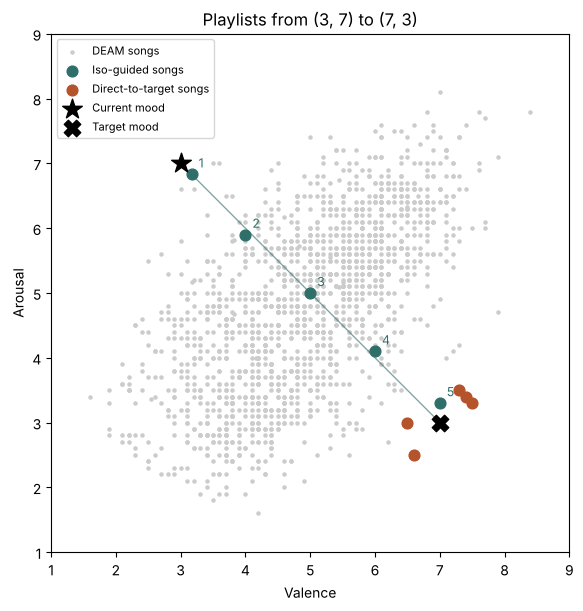

In [10]:
fig, ax = plt.subplots(figsize=(6.2, 6), constrained_layout=True)
ax.scatter(songs["valence"], songs["arousal"], s=5, color="#cccccc", label="DEAM songs")
styles = {ISO: ("#2f6f6a", "-", "Iso-guided"), DIRECT: ("#b5532a", "--", "Direct-to-target")}
for cond, part in session.groupby("condition", sort=False):
    color, ls, label = styles[cond]
    ax.plot(part["target_valence"], part["target_arousal"], ls, color=color, lw=1, alpha=0.6)
    ax.scatter(part["song_valence"], part["song_arousal"], s=60, color=color, label=f"{label} songs", zorder=3)
    if cond == ISO:
        for r in part.itertuples():
            ax.annotate(str(r.step), (r.song_valence, r.song_arousal), xytext=(5, 5),
                        textcoords="offset points", fontsize=9, color=color)
ax.scatter(*current.as_array(), marker="*", s=220, color="black", label="Current mood", zorder=4)
ax.scatter(*target.as_array(), marker="X", s=140, color="black", label="Target mood", zorder=4)
ax.set(xlim=(SCALE_MIN, SCALE_MAX), ylim=(SCALE_MIN, SCALE_MAX), aspect="equal",
       xlabel="Valence", ylabel="Arousal",
       title=f"Playlists from ({current.valence:g}, {current.arousal:g}) to ({target.valence:g}, {target.arousal:g})")
ax.legend(fontsize=8)
fig.savefig(RESULTS_DIR / "example_paths.png", dpi=150)
plt.show()

## 6. Checks *(Lisa)*

Small tests on a toy song set with one song on every integer grid point, so we
know the exact right answer. The full suite, including audio fixtures and the
order-bias checks, is `python -m unittest discover -s tests -v`. Real DEAM
tests in that suite skip until `data/DEAM/` (or `DEAM_DATA_DIR`) is present.

In [ ]:
v, a = np.meshgrid(np.arange(1, 10), np.arange(1, 10))
toy = pd.DataFrame({"song_id": np.arange(81) + 100, "valence": v.ravel().astype(float),
                    "arousal": a.ravel().astype(float), "audio_path": None})
toy_r = SongRetriever(toy)

# Iso path: starts at current, ends at target, even steps
p = iso_path(Mood(3, 7), Mood(7, 3))
assert np.allclose(p[0], [3, 7]) and np.allclose(p[-1], [7, 3])
assert np.allclose(np.diff(p, axis=0), [1, -1])

# Direct path: every point at the target
assert np.allclose(direct_path(Mood(7, 3)), [7, 3])

# Legacy retrieval: iso finds the exact grid songs, and no song is repeated
legacy = build_session(toy_r, Mood(3, 7), Mood(7, 3), allocation="iso_first")
assert legacy["song_id"].is_unique and len(legacy) == 2 * N_STEPS
assert (legacy.query("condition == 'iso'")["distance"] == 0).all()

# Joint retrieval keeps unique songs. Iso steps before the target still hit
# the grid; the exact target song is shared with the direct playlist.
joint = build_session(toy_r, Mood(3, 7), Mood(7, 3), allocation="joint")
assert joint["song_id"].is_unique and len(joint) == 2 * N_STEPS
assert (joint.query("condition == 'iso' and step < 5")["distance"] == 0).all()

# Invalid moods are rejected
try:
    Mood(0, 5)
    raise AssertionError("Mood(0, 5) should fail")
except ValueError:
    pass

print("All planner checks passed")

## 7. Match quality across many moods

The direct playlist needs 5 songs at the **same** point, so its songs may be
further from their target than the iso songs even when song allocation is fair.
That difference is a property of the waypoints. A separate, unwanted difference
comes from building one playlist before the other. The next cell reports both,
on the same 300 mood pairs, for `iso_first`, `direct_first`, and `joint`.

In [ ]:
rng = np.random.default_rng(0)
rows = []
for _ in range(300):
    c, t = rng.integers(1, 10, size=2), rng.integers(1, 10, size=2)
    current_m, target_m = Mood(int(c[0]), int(c[1])), Mood(int(t[0]), int(t[1]))
    for allocation in ("iso_first", "direct_first", "joint"):
        quality = match_quality(
            build_session(retriever, current_m, target_m, allocation=allocation)
        )
        rows.append({
            "allocation": allocation,
            "iso_mean": quality.loc["iso", "mean"],
            "direct_mean": quality.loc["direct", "mean"],
        })
mq = pd.DataFrame(rows)
mq.groupby("allocation")[["iso_mean", "direct_mean"]].mean().round(3)

## 8. Summary and points for the team

**Done**
- DEAM loading and cleaning, coverage plot, and gap table.
- Path planner (iso-guided and direct-to-target) and song retrieval, with why-card text.
- Joint song allocation so the two playlists do not depend on build order. The original iso-first rule is still available.
- Audio paths are resolved from `data/DEAM` or `DEAM_DATA_DIR`. Missing and undecodable MP3s are dropped once any MP3s are found.

**To decide before the pilot**
1. **Match quality differs between conditions** because the direct playlist asks for five songs at one point and the iso playlist asks for a path. Report `match_quality()` for every participant. The earlier ratings-only means (about 0.57 iso and 1.10 direct over 300 pairs) used iso-first and are not a joint-allocation result.
2. **Allocation rule.** `build_session` now defaults to `allocation="joint"`. `allocation="iso_first"` reproduces the previous notebook. Please approve the joint rule before the pilot. When both conditions need the same number of songs at the same point, a remaining name tie gives the single closest of those songs to `direct` and then alternates.
3. **Slider limits:** the corners of the mood space have almost no songs. We could limit the sliders (for example to 2 to 8) or show the gap warning in the app.
4. **Spread cutoff:** the 90th percentile is our current choice. It is computed after the audio filter, so the cutoff can move once MP3s are present. Please confirm before we freeze it.

**Next in the timeline:** Tiffany can call `build_session(retriever, Mood(...), Mood(...))`.
Each row has `audio_path` for playback and `why` for the why-card. `audio_path` is empty until the DEAM MP3s are on disk.